In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

print("All libraries imported successfully!")

All libraries imported successfully!


In [2]:
import os

file_path = r"C:\Users\Hasthika Jain\Online Retail.xlsx"

if os.path.exists(file_path):
    print("Excel file found!")
else:
    print("Excel file not found. Please check the file location.")

Excel file found!


In [5]:
import pandas as pd

df = pd.read_excel(file_path, engine="openpyxl")

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Dataset loaded successfully!
Number of rows: 541909
Number of columns: 8


In [9]:
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


In [10]:
missing_values = df.isnull().sum()

print("Missing values in each column:")
print(missing_values)

Missing values in each column:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


In [11]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 5268


In [12]:
print("Rows before cleaning:", len(retail_df))

retail_df = retail_df.drop_duplicates()

print("Rows after cleaning:", len(retail_df))

print("Remaining duplicate rows:", retail_df.duplicated().sum())

NameError: name 'retail_df' is not defined

In [13]:
retail_df = df.copy()

print("Working copy created successfully!")
print("Total rows:", len(retail_df))

Working copy created successfully!
Total rows: 541909


In [14]:
print("Rows before cleaning:", len(retail_df))

retail_df = retail_df.drop_duplicates()

print("Rows after cleaning:", len(retail_df))
print("Remaining duplicates:", retail_df.duplicated().sum())

Rows before cleaning: 541909
Rows after cleaning: 536641
Remaining duplicates: 0


In [15]:
missing_percentage = (
    retail_df.isnull().sum() / len(retail_df)
) * 100

print("Missing values in each column:")
print(retail_df.isnull().sum())

print("\nMissing-value percentages:")
print(missing_percentage.round(2))

Missing values in each column:
InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135037
Country             0
dtype: int64

Missing-value percentages:
InvoiceNo       0.00
StockCode       0.00
Description     0.27
Quantity        0.00
InvoiceDate     0.00
UnitPrice       0.00
CustomerID     25.16
Country         0.00
dtype: float64


In [16]:
retail_df["Revenue"] = retail_df["Quantity"] * retail_df["UnitPrice"]

print("Revenue column created successfully!")

retail_df[["Quantity", "UnitPrice", "Revenue"]].head()

Revenue column created successfully!


,Quantity,UnitPrice,Revenue
0,6,2.55,15.30
1,6,3.39,20.34
2,8,2.75,22.00
3,6,3.39,20.34
4,6,3.39,20.34


In [17]:
total_revenue = retail_df["Revenue"].sum()

print("Total transaction revenue: £{:,.2f}".format(total_revenue))

Total transaction revenue: £9,726,006.95


In [18]:
country_sales = retail_df.groupby("Country")["Revenue"].sum()

top_10_countries = country_sales.sort_values(ascending=False).head(10)

print("Top 10 Countries by Revenue:")
display(top_10_countries)

Top 10 Countries by Revenue:


Country
United Kingdom    8167128.184
Netherlands        284661.540
EIRE               262993.380
Germany            221509.470
France             197317.110
Australia          137009.770
Switzerland         56363.050
Spain               54756.030
Belgium             40910.960
Sweden              36585.410
Name: Revenue, dtype: float64

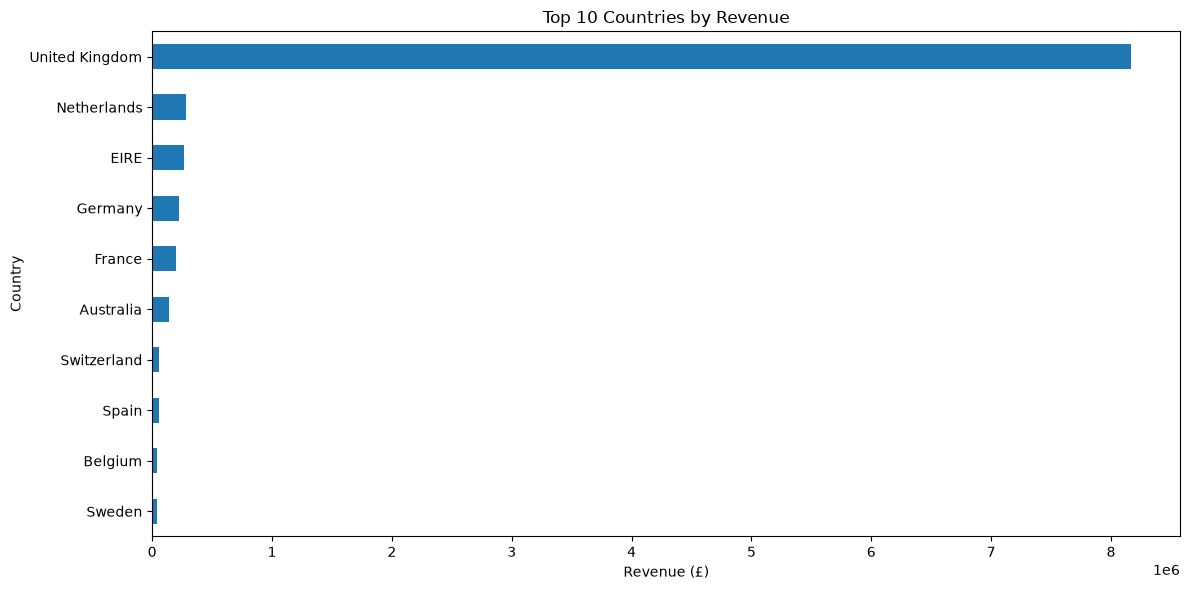

In [19]:
plt.figure(figsize=(12, 6))

top_10_countries.sort_values().plot(kind="barh")

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Country")
plt.tight_layout()

plt.show()

In [20]:
retail_df["InvoiceDate"] = pd.to_datetime(retail_df["InvoiceDate"])

retail_df["Month"] = retail_df["InvoiceDate"].dt.to_period("M")

monthly_sales = retail_df.groupby("Month")["Revenue"].sum()

print("Monthly Revenue:")
display(monthly_sales)

Monthly Revenue:


Month
2010-12     746723.610
2011-01     558448.560
2011-02     497026.410
2011-03     682013.980
2011-04     492367.841
2011-05     722094.100
2011-06     689977.230
2011-07     680156.991
2011-08     681386.460
2011-09    1017596.682
2011-10    1069368.230
2011-11    1456145.800
2011-12     432701.060
Freq: M, Name: Revenue, dtype: float64

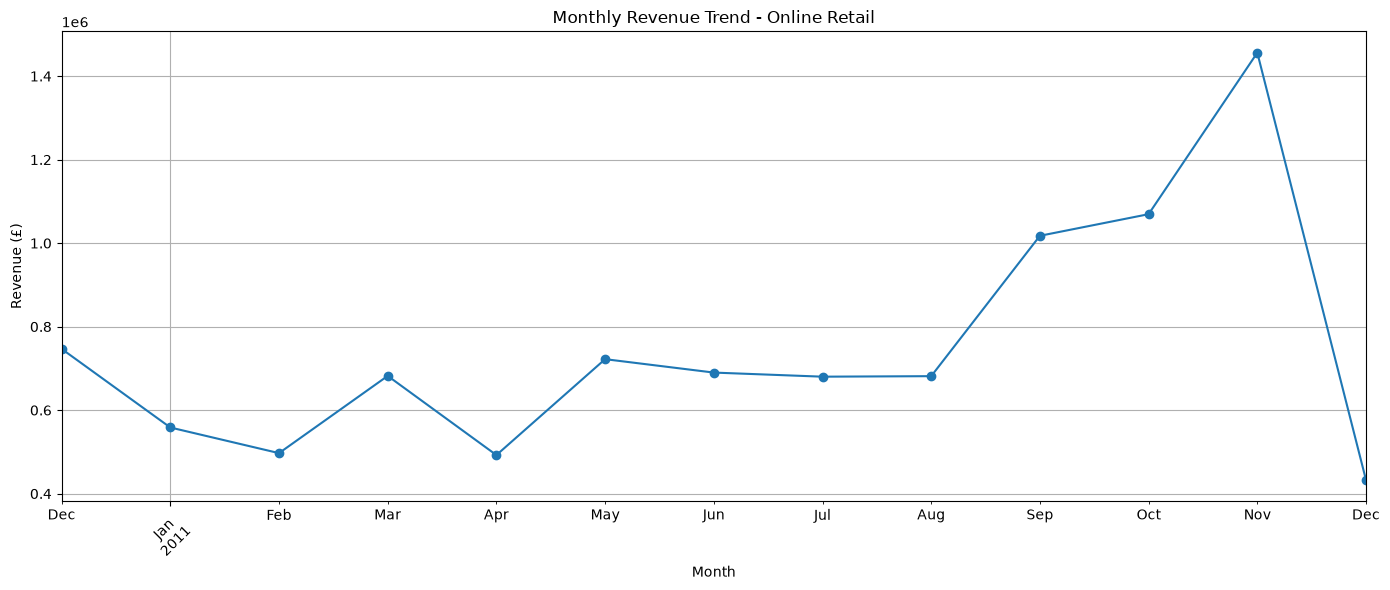

In [21]:
plt.figure(figsize=(14, 6))

monthly_sales.plot(kind="line", marker="o")

plt.title("Monthly Revenue Trend - Online Retail")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

plt.show()

In [22]:
top_products = (
    retail_df.groupby("Description")["Quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 Best-Selling Products:")
display(top_products)

Top 10 Best-Selling Products:


Description
WORLD WAR 2 GLIDERS ASSTD DESIGNS     53751
JUMBO BAG RED RETROSPOT               47260
POPCORN HOLDER                        36322
ASSORTED COLOUR BIRD ORNAMENT         36282
PACK OF 72 RETROSPOT CAKE CASES       36016
WHITE HANGING HEART T-LIGHT HOLDER    35298
RABBIT NIGHT LIGHT                    30631
MINI PAINT SET VINTAGE                26437
PACK OF 12 LONDON TISSUES             26299
PACK OF 60 PINK PAISLEY CAKE CASES    24719
Name: Quantity, dtype: int64

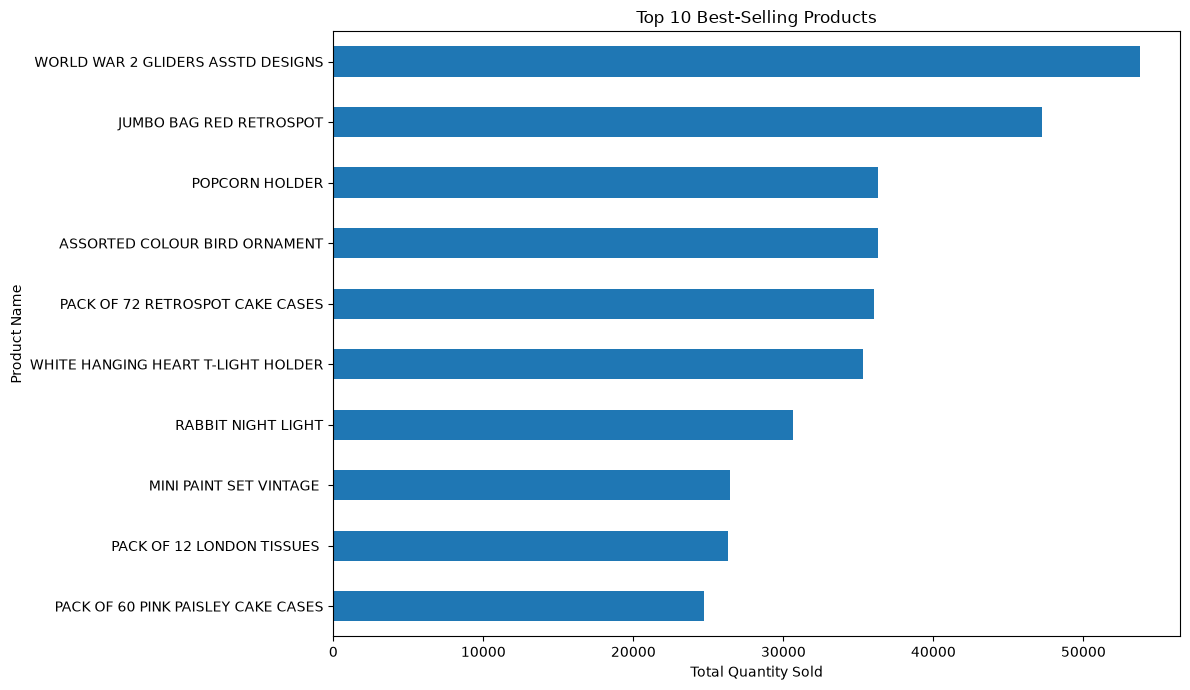

In [23]:
plt.figure(figsize=(12, 7))

top_products.sort_values().plot(kind="barh")

plt.title("Top 10 Best-Selling Products")
plt.xlabel("Total Quantity Sold")
plt.ylabel("Product Name")

plt.tight_layout()
plt.show()

In [24]:
plt.figure(figsize=(12, 6))

top_customers.sort_values().plot(kind="barh")

plt.title("Top 10 Customers by Revenue")
plt.xlabel("Total Revenue (£)")
plt.ylabel("Customer ID")

plt.tight_layout()
plt.show()

NameError: name 'top_customers' is not defined

<Figure size 1200x600 with 0 Axes>

In [25]:
customer_data = retail_df.dropna(subset=["CustomerID"]).copy()

top_customers = (
    customer_data.groupby("CustomerID")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 Customers by Revenue:")
display(top_customers)

Top 10 Customers by Revenue:


CustomerID
14646.0    279489.02
18102.0    256438.49
17450.0    187322.17
14911.0    132458.73
12415.0    123725.45
14156.0    113214.59
17511.0     88125.38
16684.0     65892.08
13694.0     62690.54
15311.0     59284.19
Name: Revenue, dtype: float64

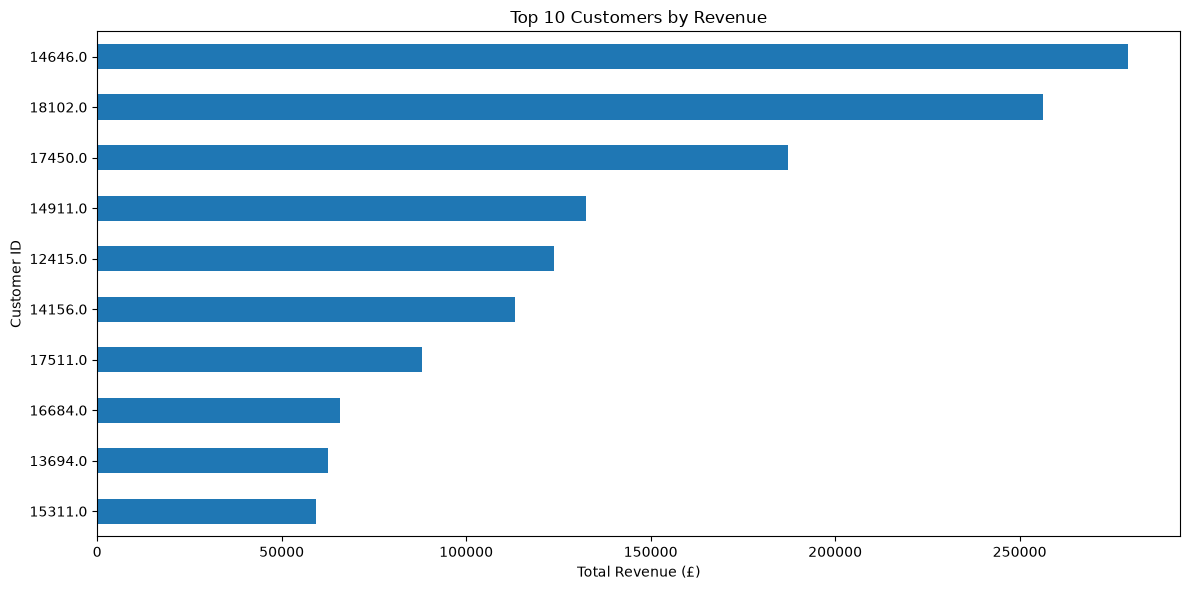

In [26]:
plt.figure(figsize=(12, 6))

top_customers.sort_values().plot(kind="barh")

plt.title("Top 10 Customers by Revenue")
plt.xlabel("Total Revenue (£)")
plt.ylabel("Customer ID")

plt.tight_layout()
plt.show()

In [27]:
orders_by_country = (
    retail_df.groupby("Country")["InvoiceNo"]
    .nunique()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 Countries by Number of Orders:")
display(orders_by_country)

Top 10 Countries by Number of Orders:


Country
United Kingdom    23494
Germany             603
France              461
EIRE                360
Belgium             119
Spain               105
Netherlands         101
Switzerland          74
Portugal             71
Australia            69
Name: InvoiceNo, dtype: int64

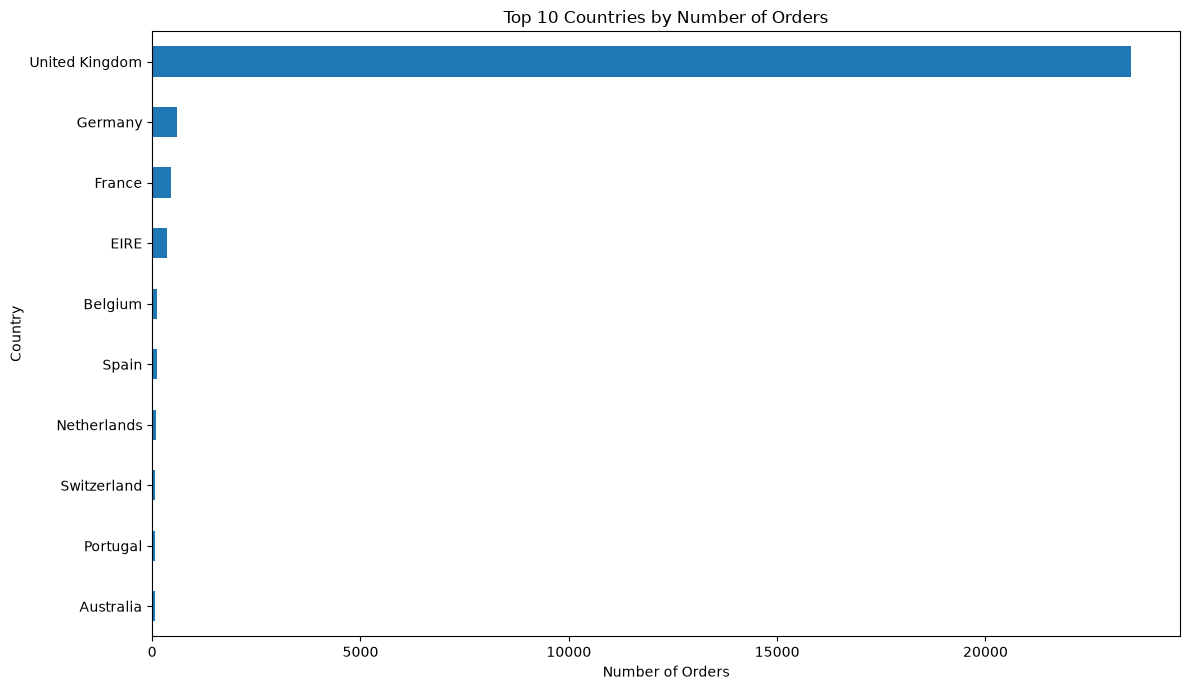

In [28]:
plt.figure(figsize=(12, 7))

orders_by_country.sort_values().plot(kind="barh")

plt.title("Top 10 Countries by Number of Orders")
plt.xlabel("Number of Orders")
plt.ylabel("Country")

plt.tight_layout()
plt.show()

In [29]:
retail_df["DayOfWeek"] = retail_df["InvoiceDate"].dt.day_name()

daily_sales = retail_df.groupby("DayOfWeek")["Revenue"].sum()

day_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

daily_sales = daily_sales.reindex(day_order)

print("Revenue by Day of the Week:")
display(daily_sales)

Revenue by Day of the Week:


DayOfWeek
Monday       1584895.301
Tuesday      1965703.611
Wednesday    1730088.430
Thursday     2108701.530
Friday       1537958.621
Saturday             NaN
Sunday        798659.461
Name: Revenue, dtype: float64

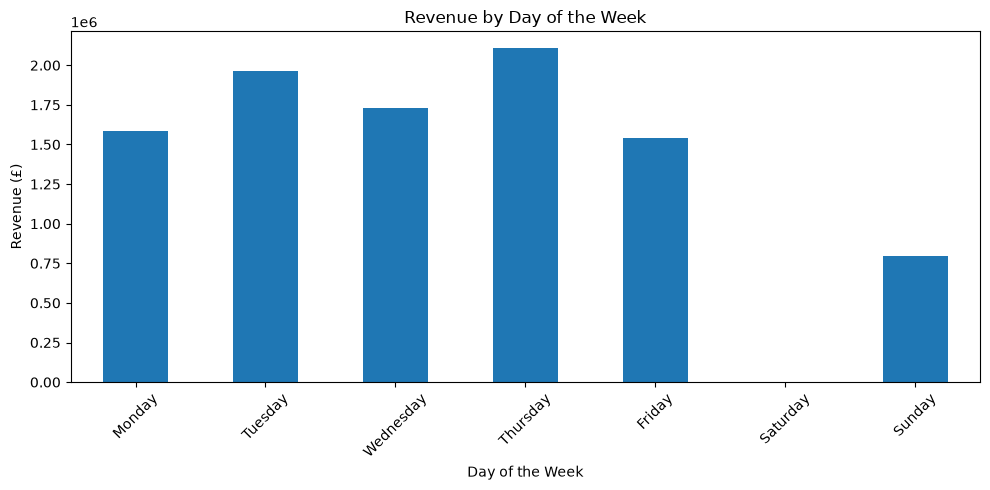

In [30]:
daily_sales_chart = daily_sales.fillna(0)

plt.figure(figsize=(10, 5))

daily_sales_chart.plot(kind="bar")

plt.title("Revenue by Day of the Week")
plt.xlabel("Day of the Week")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [31]:
invoice_revenue = retail_df.groupby("InvoiceNo")["Revenue"].sum()

average_order_value = invoice_revenue.mean()

print("Average Order Value: £{:.2f}".format(average_order_value))

Average Order Value: £375.52


In [32]:
cancelled_orders = retail_df[
    retail_df["InvoiceNo"].astype(str).str.startswith("C")
]

cancelled_count = cancelled_orders["InvoiceNo"].nunique()

print("Number of Cancelled Orders:", cancelled_count)

display(cancelled_orders.head())

Number of Cancelled Orders: 3836


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,Month,DayOfWeek
141,C536379,D,Discount,-1,2010-12-01 09:41:00,27.50,14527.0,United Kingdom,-27.50,2010-12,Wednesday
154,C536383,35004C,SET OF 3 COLOURED FLYING DUCKS,-1,2010-12-01 09:49:00,4.65,15311.0,United Kingdom,-4.65,2010-12,Wednesday
235,C536391,22556,PLASTERS IN TIN CIRCUS PARADE,-12,2010-12-01 10:24:00,1.65,17548.0,United Kingdom,-19.80,2010-12,Wednesday
236,C536391,21984,PACK OF 12 PINK PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom,-6.96,2010-12,Wednesday
237,C536391,21983,PACK OF 12 BLUE PAISLEY TISSUES,-24,2010-12-01 10:24:00,0.29,17548.0,United Kingdom,-6.96,2010-12,Wednesday


In [33]:
completed_orders = retail_df[
    ~retail_df["InvoiceNo"].astype(str).str.startswith("C")
].copy()

total_revenue_completed = completed_orders["Revenue"].sum()

print("Total Revenue (Excluding Cancelled Invoices): £{:.2f}".format(
    total_revenue_completed
))

print("Original Total Revenue: £{:.2f}".format(
    retail_df["Revenue"].sum()
))

Total Revenue (Excluding Cancelled Invoices): £10619986.68
Original Total Revenue: £9726006.95


In [34]:
```python
completed_orders["Month"] = pd.to_datetime(
    completed_orders["InvoiceDate"]
).dt.to_period("M")

monthly_revenue = completed_orders.groupby("Month")["Revenue"].sum()

print("Monthly Revenue:")
display(monthly_revenue)

highest_month = monthly_revenue.idxmax()
highest_revenue = monthly_revenue.max()

print("Highest Revenue Month:", highest_month)
print("Highest Monthly Revenue: £{:.2f}".format(highest_revenue))
```


SyntaxError: invalid syntax (1642762459.py, line 1)

In [35]:
completed_orders["Month"] = pd.to_datetime(
    completed_orders["InvoiceDate"]
).dt.to_period("M")

monthly_revenue = completed_orders.groupby("Month")["Revenue"].sum()

print("Monthly Revenue:")
display(monthly_revenue)

highest_month = monthly_revenue.idxmax()
highest_revenue = monthly_revenue.max()

print("Highest Revenue Month:", highest_month)
print("Highest Monthly Revenue: £{:.2f}".format(highest_revenue))

Monthly Revenue:


Month
2010-12     821452.730
2011-01     689811.610
2011-02     522545.560
2011-03     716215.260
2011-04     536968.491
2011-05     769296.610
2011-06     760547.010
2011-07     718076.121
2011-08     735717.260
2011-09    1056435.192
2011-10    1151263.730
2011-11    1503866.780
2011-12     637790.330
Freq: M, Name: Revenue, dtype: float64

Highest Revenue Month: 2011-11
Highest Monthly Revenue: £1503866.78


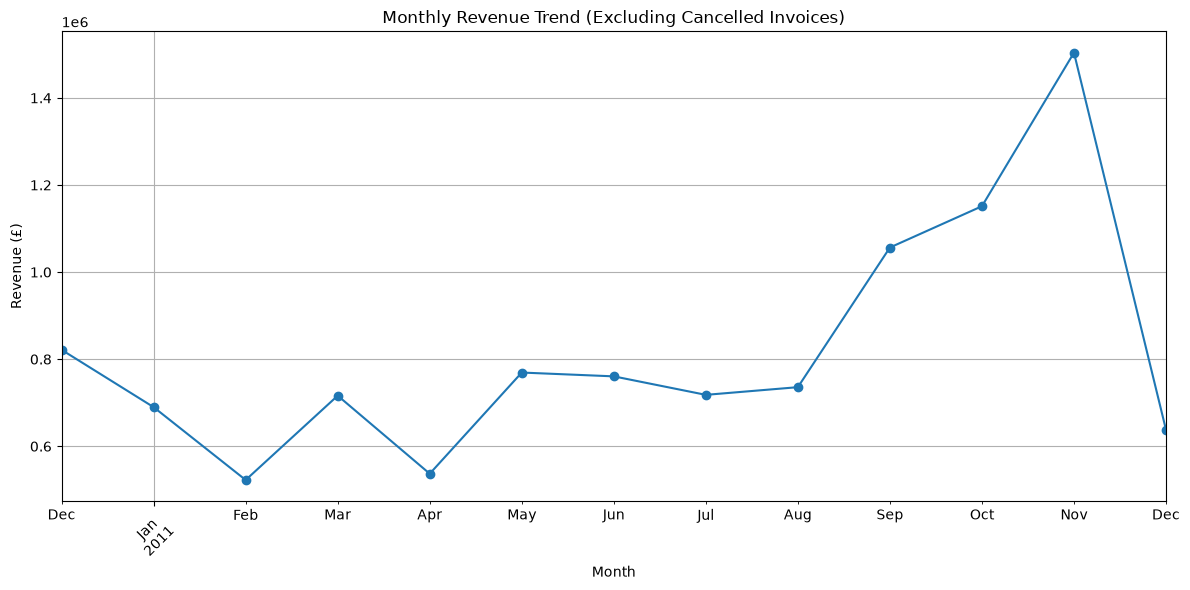

In [36]:
plt.figure(figsize=(12, 6))

monthly_revenue.plot(kind="line", marker="o")

plt.title("Monthly Revenue Trend (Excluding Cancelled Invoices)")
plt.xlabel("Month")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()

plt.show()

In [37]:
product_revenue = (
    completed_orders.groupby("Description")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 Products by Revenue:")
display(product_revenue)

Top 10 Products by Revenue:


Description
DOTCOM POSTAGE                        206248.77
REGENCY CAKESTAND 3 TIER              174156.54
PAPER CRAFT , LITTLE BIRDIE           168469.60
WHITE HANGING HEART T-LIGHT HOLDER    106236.72
PARTY BUNTING                          99445.23
JUMBO BAG RED RETROSPOT                94159.81
MEDIUM CERAMIC TOP STORAGE JAR         81700.92
POSTAGE                                78101.88
Manual                                 77752.82
RABBIT NIGHT LIGHT                     66870.03
Name: Revenue, dtype: float64

In [38]:
customer_data = completed_orders.dropna(subset=["CustomerID"]).copy()

top_customers = (
    customer_data.groupby("CustomerID")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 Customers by Revenue:")
display(top_customers)
```


SyntaxError: invalid syntax (4011189976.py, line 12)

In [39]:
customer_data = completed_orders.dropna(subset=["CustomerID"]).copy()

top_customers = (
    customer_data.groupby("CustomerID")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 Customers by Revenue:")
display(top_customers)

Top 10 Customers by Revenue:


CustomerID
14646.0    280206.02
18102.0    259657.30
17450.0    194390.79
16446.0    168472.50
14911.0    143711.17
12415.0    124914.53
14156.0    117210.08
17511.0     91062.38
16029.0     80850.84
12346.0     77183.60
Name: Revenue, dtype: float64

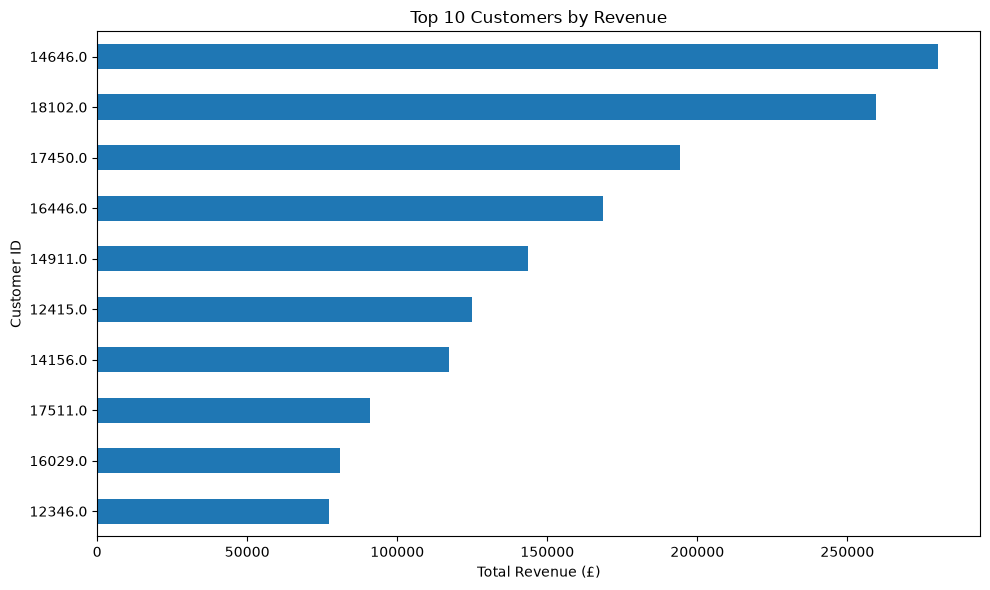

In [40]:
plt.figure(figsize=(10, 6))

top_customers.sort_values().plot(kind="barh")

plt.title("Top 10 Customers by Revenue")
plt.xlabel("Total Revenue (£)")
plt.ylabel("Customer ID")
plt.tight_layout()

plt.show()

In [41]:
country_revenue = (
    completed_orders.groupby("Country")["Revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 Countries by Revenue:")
display(country_revenue)

Top 10 Countries by Revenue:


Country
United Kingdom    8979619.974
Netherlands        285446.340
EIRE               283140.520
Germany            228678.400
France             209625.370
Australia          138453.810
Spain               61558.560
Switzerland         57067.600
Belgium             41196.340
Sweden              38367.830
Name: Revenue, dtype: float64

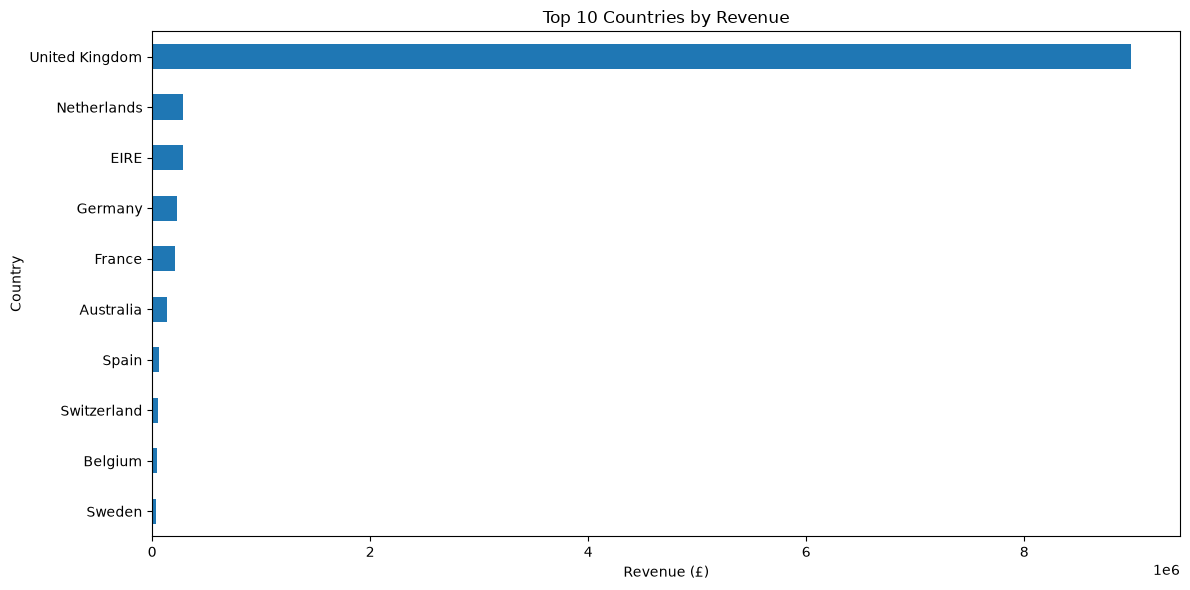

In [42]:
plt.figure(figsize=(12, 6))

country_revenue.sort_values().plot(kind="barh")

plt.title("Top 10 Countries by Revenue")
plt.xlabel("Revenue (£)")
plt.ylabel("Country")
plt.tight_layout()
plt.show()

In [43]:
cancelled_count = retail_df[
    retail_df["InvoiceNo"].astype(str).str.startswith("C")
]["InvoiceNo"].nunique()

completed_count = completed_orders["InvoiceNo"].nunique()

print("Number of Cancelled Invoices:", cancelled_count)
print("Number of Non-Cancelled Invoices:", completed_count)

Number of Cancelled Invoices: 3836
Number of Non-Cancelled Invoices: 22064


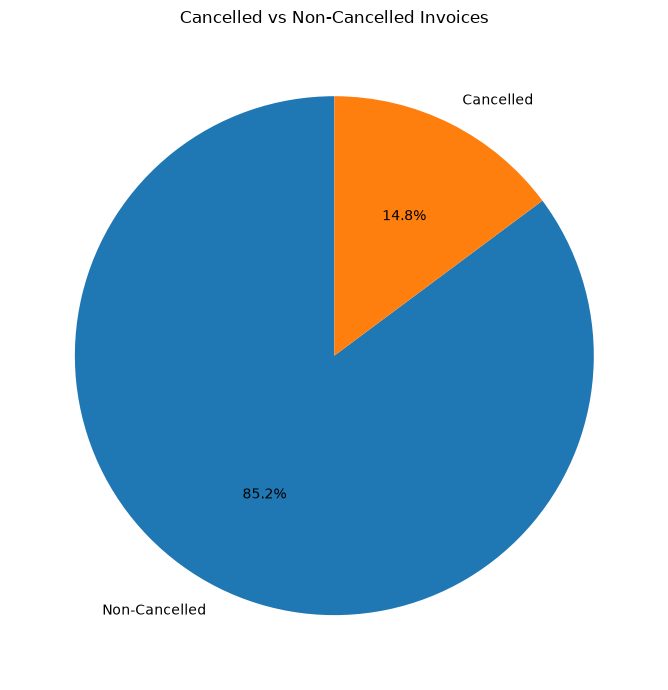

In [44]:
invoice_status = pd.Series({
    "Non-Cancelled": completed_count,
    "Cancelled": cancelled_count
})

plt.figure(figsize=(7, 7))

plt.pie(
    invoice_status,
    labels=invoice_status.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("Cancelled vs Non-Cancelled Invoices")
plt.tight_layout()
plt.show()

In [45]:
completed_orders["InvoiceDate"] = pd.to_datetime(
    completed_orders["InvoiceDate"]
)

completed_orders["Month"] = (
    completed_orders["InvoiceDate"].dt.to_period("M")
)

monthly_orders = completed_orders.groupby("Month")["InvoiceNo"].nunique()

print("Number of Invoices per Month:")
display(monthly_orders)

print("\nMonth with Highest Number of Invoices:", monthly_orders.idxmax())
print("Highest Number of Invoices:", monthly_orders.max())

Number of Invoices per Month:


Month
2010-12    1699
2011-01    1216
2011-02    1174
2011-03    1665
2011-04    1504
2011-05    1848
2011-06    1683
2011-07    1657
2011-08    1459
2011-09    1994
2011-10    2275
2011-11    3021
2011-12     869
Freq: M, Name: InvoiceNo, dtype: int64


Month with Highest Number of Invoices: 2011-11
Highest Number of Invoices: 3021


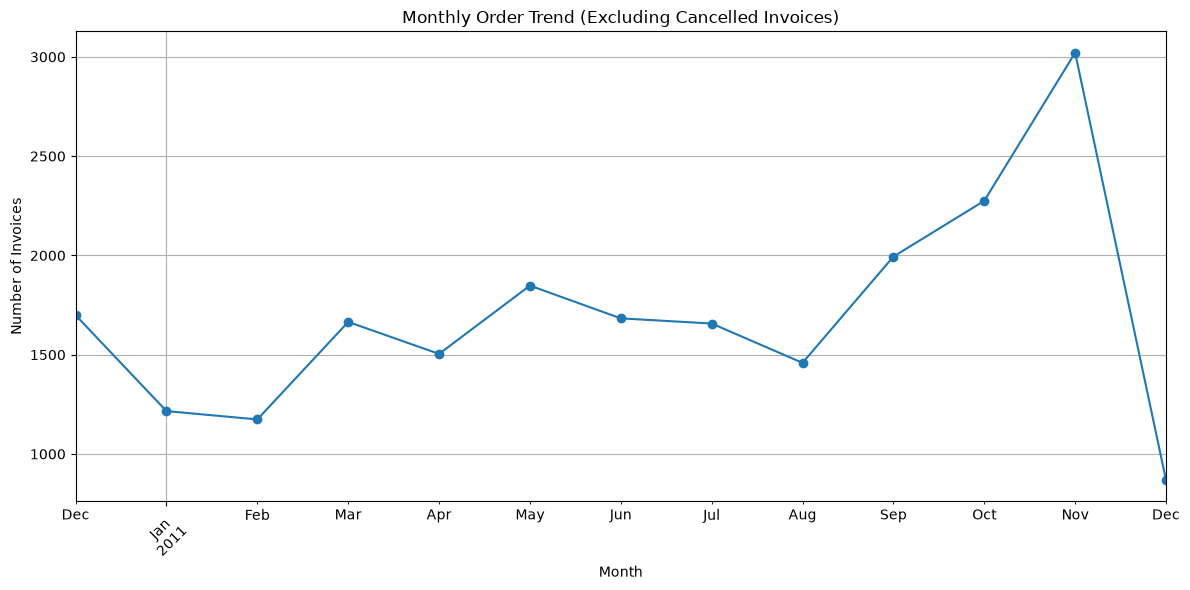

In [46]:
plt.figure(figsize=(12, 6))

monthly_orders.plot(kind="line", marker="o")

plt.title("Monthly Order Trend (Excluding Cancelled Invoices)")
plt.xlabel("Month")
plt.ylabel("Number of Invoices")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

In [47]:
day_analysis = completed_orders.copy()

day_analysis["DayOfWeek"] = day_analysis["InvoiceDate"].dt.day_name()

day_revenue = day_analysis.groupby("DayOfWeek")["Revenue"].sum()

day_order = [
    "Monday", "Tuesday", "Wednesday",
    "Thursday", "Friday", "Saturday", "Sunday"
]

day_revenue = day_revenue.reindex(day_order)

print("Revenue by Day of the Week:")
display(day_revenue)

print("\nDay with Highest Recorded Revenue:", day_revenue.idxmax())
print("Highest Recorded Revenue: £{:.2f}".format(day_revenue.max()))

Revenue by Day of the Week:


DayOfWeek
Monday       1775782.071
Tuesday      2175700.511
Wednesday    1847074.380
Thursday     2199292.570
Friday       1815346.371
Saturday             NaN
Sunday        806790.781
Name: Revenue, dtype: float64


Day with Highest Recorded Revenue: Thursday
Highest Recorded Revenue: £2199292.57


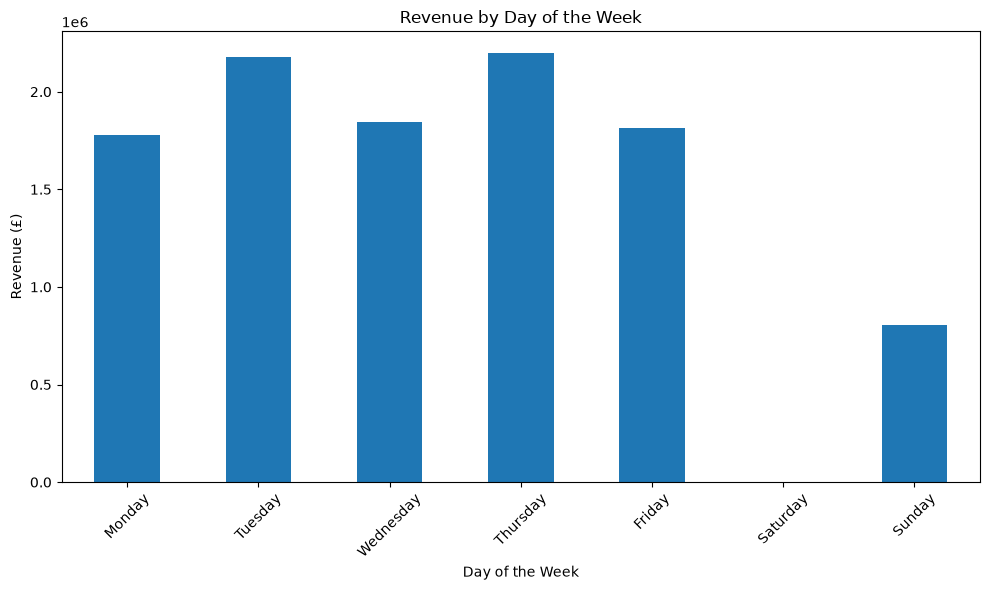

In [48]:
plt.figure(figsize=(10, 6))

day_revenue.fillna(0).plot(kind="bar")

plt.title("Revenue by Day of the Week")
plt.xlabel("Day of the Week")
plt.ylabel("Revenue (£)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [49]:
invoice_revenue = completed_orders.groupby("InvoiceNo")["Revenue"].sum()

average_order_value = invoice_revenue.mean()

print("Total Non-Cancelled Invoices:", len(invoice_revenue))
print("Average Order Value: £{:.2f}".format(average_order_value))

Total Non-Cancelled Invoices: 22064
Average Order Value: £481.33


In [50]:
unique_customers = completed_orders["CustomerID"].nunique()

total_quantity_sold = completed_orders["Quantity"].sum()

unique_products = completed_orders["StockCode"].nunique()

print("Number of Unique Customers:", unique_customers)
print("Total Quantity (Net):", total_quantity_sold)
print("Number of Unique Products:", unique_products)

Number of Unique Customers: 4339
Total Quantity (Net): 5438062
Number of Unique Products: 4059


In [51]:

total_revenue = completed_orders["Revenue"].sum()

total_invoices = completed_orders["InvoiceNo"].nunique()

unique_customers = completed_orders["CustomerID"].nunique()

unique_products = completed_orders["StockCode"].nunique()

total_quantity = completed_orders["Quantity"].sum()

cancelled_invoices = retail_df[
    retail_df["InvoiceNo"].astype(str).str.startswith("C")
]["InvoiceNo"].nunique()

print("========== ONLINE RETAIL ANALYTICS: KPI SUMMARY ==========")
print(f"Total Revenue: £{total_revenue:,.2f}")
print(f"Non-Cancelled Invoices: {total_invoices:,}")
print(f"Cancelled Invoices: {cancelled_invoices:,}")
print(f"Unique Customers: {unique_customers:,}")
print(f"Unique Products: {unique_products:,}")
print(f"Total Net Quantity: {total_quantity:,}")
print(f"Average Order Value: £{average_order_value:,.2f}")
print("==========================================================")

========== ONLINE RETAIL ANALYTICS: KPI SUMMARY ==========
Total Revenue: £10,619,986.68
Non-Cancelled Invoices: 22,064
Cancelled Invoices: 3,836
Unique Customers: 4,339
Unique Products: 4,059
Total Net Quantity: 5,438,062
Average Order Value: £481.33


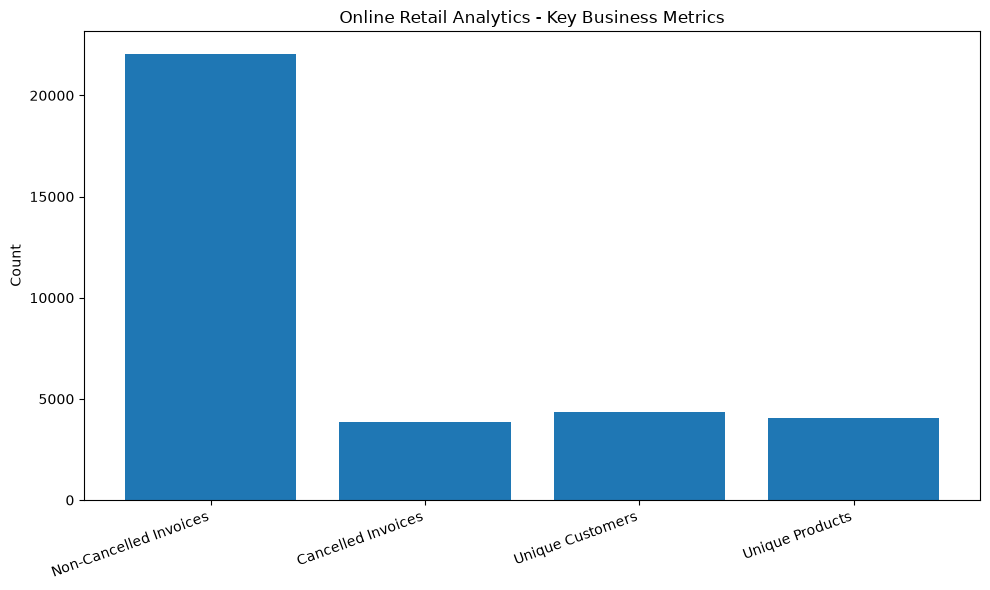

In [52]:

kpi_labels = [
    "Non-Cancelled Invoices",
    "Cancelled Invoices",
    "Unique Customers",
    "Unique Products"
]

kpi_values = [
    total_invoices,
    cancelled_invoices,
    unique_customers,
    unique_products
]

plt.figure(figsize=(10, 6))

plt.bar(kpi_labels, kpi_values)

plt.title("Online Retail Analytics - Key Business Metrics")
plt.ylabel("Count")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

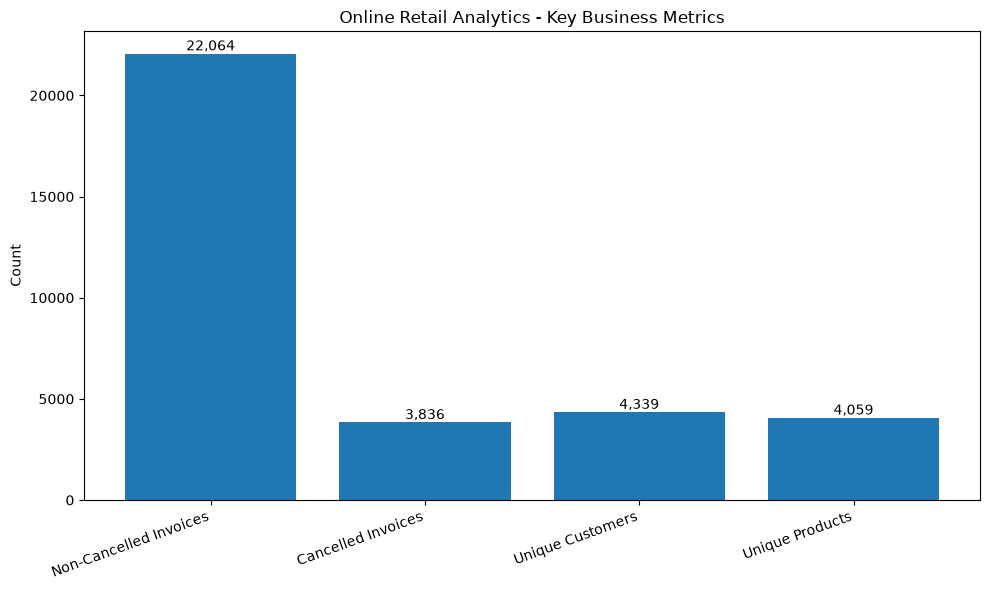

In [53]:
plt.figure(figsize=(10, 6))

bars = plt.bar(kpi_labels, kpi_values)

plt.title("Online Retail Analytics - Key Business Metrics")
plt.ylabel("Count")
plt.xticks(rotation=20, ha="right")

for bar in bars:
    height = bar.get_height()
    plt.text(
        bar.get_x() + bar.get_width() / 2,
        height,
        f"{int(height):,}",
        ha="center",
        va="bottom"
    )

plt.tight_layout()
plt.show()